# Milestone 3, Part 1.3: stress tests

How much worse does the same-story model get when the headlines are damaged, when the inputs look different from training, or when same-story pairs are rarer than in our test set?

Models (all from Milestone 2, nothing is retrained here):
- **TF-IDF** baseline
- **Pretrained MiniLM** (no fine-tuning)
- **Fine-tuned MiniLM** (the deployed model, `models/m2_final/`, copied from the RTX 3080 run)

Rules are the same as Milestone 2: each model's threshold is picked on the **clean** validation set and then kept fixed, like in deployment. Metrics are the Milestone 2 ones (precision, recall, F1, ROC-AUC, PR-AUC), on the 2,457 test pairs. For the fine-tuned model we add 95% intervals (bootstrap, 1,000 resamples).

Tests:
1. **Damaged inputs:** typos, word dropout, word masking, only the start of the headline kept, all caps, accents removed (3 strengths where it makes sense)
2. **Rare same-story pairs:** test resampled so same-story pairs are 24% (a real Top Stories page), 10% and 5%
3. **Out-of-distribution inputs:** headlines from local news pages, which the model never saw
4. **Unsure band:** how many pairs score close to the threshold, and how accurate the model is outside that band

Outputs go to `outputs/milestone3/stress/`.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'pairs').is_dir())
sys.path.insert(0, str(ROOT))
from src.m2_common import *          # data, metrics and scoring shared with Milestone 2
from src.m3_stress import *          # corruptions and stress-test helpers

OUT = ROOT / 'outputs' / 'milestone3' / 'stress'
OUT.mkdir(parents=True, exist_ok=True)
pairs = load_pairs()
TRAIN, VAL, TEST = pairs['train'], pairs['val'], pairs['test']
print('device:', DEVICE)

finetuned, pretrained = load_biencoder(MODELS / 'm2_final'), load_biencoder()
SCORERS = {
    'TF-IDF': tfidf_scorer(TRAIN),
    'Pretrained MiniLM': lambda df: pair_scores(pretrained, df),
    'Fine-tuned MiniLM': lambda df: pair_scores(finetuned, df),
}
VAL_SCORES = {name: f(VAL) for name, f in SCORERS.items()}
THRESHOLD = {name: best_threshold(VAL.label.values, s) for name, s in VAL_SCORES.items()}
CLEAN = {name: f(TEST) for name, f in SCORERS.items()}
check = pd.DataFrame({name: evaluate(TEST.label.values, CLEAN[name], THRESHOLD[name]) for name in SCORERS}).T
check.insert(0, 'threshold', pd.Series(THRESHOLD))
check.round(3)   # should match Milestone 2: fine-tuned threshold 0.724, test F1 0.906

device: cpu


,threshold,precision,recall,f1,accuracy,roc_auc,pr_auc
TF-IDF,0.042,0.868,0.688,0.768,0.805,0.834,0.846
Pretrained MiniLM,0.294,0.893,0.836,0.863,0.876,0.947,0.945
Fine-tuned MiniLM,0.724,0.916,0.896,0.906,0.913,0.971,0.966


## 1. What the damage looks like

In [2]:
example = TEST.headline_a.iloc[0]
rows = [('clean', '', example)]
for name, levels in CORRUPTIONS.items():
    for level, fn in levels:
        rows.append((name, level, fn(clean_headline(example), np.random.default_rng(SEED))))
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows, columns=['test', 'level', 'headline'])

,test,level,headline
0,clean,,Braid: Private data of millions of Albertans allegedly leaked for separatist campaign
1,typos (share of letters),0.05,Braid: Private data of millions of Albertans allegedly leaked for separatist campaign
2,typos (share of letters),0.1,Braiqd: Private data of miloions fo Albertans allegedly lemakde for separatisto campaifgn
3,typos (share of letters),0.2,Braiqd: Prvamte da of miilliovns oof Albertanz allemedyl leaked for sepaoatipt campagn
4,word dropout (share of words),0.1,Braid: Private data millions of Albertans allegedly leaked for separatist campaign
5,word dropout (share of words),0.2,Braid: Private data millions of Albertans allegedly for separatist
6,word dropout (share of words),0.3,Braid: Private data millions of Albertans allegedly for separatist
7,word masking (share of words),0.1,Braid: Private data _ millions of Albertans allegedly leaked for separatist campaign
8,word masking (share of words),0.2,Braid: Private data _ millions of Albertans allegedly _ for separatist _
9,word masking (share of words),0.3,Braid: Private data _ millions of Albertans allegedly _ for separatist _


## 2. Damaged inputs

Each damage is applied to every distinct headline once (fixed seed), then all three models score the damaged test pairs with their clean-val threshold.

In [3]:
labels, rows = TEST.label.values, []
for name, f in SCORERS.items():
    m = evaluate(labels, CLEAN[name], THRESHOLD[name])
    rows.append({'test': 'clean', 'level': 0, 'model': name, **m})
for test, levels in CORRUPTIONS.items():
    for level, fn in levels:
        damaged = corrupt_pairs(TEST, fn)
        for name, f in SCORERS.items():
            t0 = time.perf_counter()
            s = f(damaged)
            rows.append({'test': test, 'level': level, 'model': name, **evaluate(labels, s, THRESHOLD[name]),
                         'seconds': time.perf_counter() - t0, 'scores': s})
        print(f'{test:34s} {level:.2f} done', flush=True)
stress = pd.DataFrame(rows)

# 95% intervals for the deployed model
ft = stress.model == 'Fine-tuned MiniLM'
for i in stress.index[ft]:
    s = CLEAN['Fine-tuned MiniLM'] if stress.at[i, 'test'] == 'clean' else stress.at[i, 'scores']
    (f_lo, f_hi), (a_lo, a_hi) = bootstrap_ci(labels, s, THRESHOLD['Fine-tuned MiniLM'])
    stress.loc[i, ['f1_lo', 'f1_hi', 'pr_auc_lo', 'pr_auc_hi']] = [f_lo, f_hi, a_lo, a_hi]

stress.drop(columns='scores').to_csv(OUT / 'stress_results.csv', index=False)
stress.pivot_table(index=['test', 'level'], columns='model', values='f1', sort=False).round(3)

typos (share of letters)           0.05 done


typos (share of letters)           0.10 done


typos (share of letters)           0.20 done


word dropout (share of words)      0.10 done


word dropout (share of words)      0.20 done


word dropout (share of words)      0.30 done


... (5 outputs left out)

only start kept (share removed)    0.75 done


all caps                           1.00 done


accents removed                    1.00 done


model                                  TF-IDF  Pretrained MiniLM  \
test                            level                              
clean                           0.00    0.768              0.863   
typos (share of letters)        0.05    0.684              0.805   
                                0.10    0.594              0.746   
                                0.20    0.462              0.645   
word dropout (share of words)   0.10    0.731              0.825   
                                0.20    0.691              0.777   
                                0.30    0.639              0.726   
word masking (share of words)   0.10    0.731              0.829   
                                0.20    0.691              0.800   
                                0.30    0.639              0.766   
only start kept (share removed) 0.25    0.694              0.798   
                                0.50    0.556              0.687   
                                0.75    0.356              0.524   
all caps                        1.00    0.768              0.782   
accents removed                 1.00    0.761              0.863   

model                                  Fine-tuned MiniLM  
test                            level                     
clean                           0.00               0.906  
typos (share of letters)        0.05               0.851  
                                0.10               0.790  
                                0.20               0.691  
word dropout (share of words)   0.10               0.866  
                                0.20               0.827  
                                0.30               0.789  
word masking (share of words)   0.10               0.870  
                                0.20               0.837  
                                0.30               0.804  
only start kept (share removed) 0.25               0.843  
                                0.50               0.740  
                                0.75               0.597  
all caps                        1.00               0.833  
accents removed                 1.00               0.910

In [4]:
cols = ['precision', 'recall', 'f1', 'f1_lo', 'f1_hi', 'roc_auc', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi']
stress[ft].set_index(['test', 'level'])[cols].round(3)   # deployed model, with 95% intervals

precision  recall     f1  f1_lo  f1_hi  \
test                            level                                           
clean                           0.00       0.916   0.896  0.906  0.893  0.917   
typos (share of letters)        0.05       0.861   0.841  0.851  0.835  0.866   
                                0.10       0.772   0.809  0.790  0.771  0.808   
                                0.20       0.600   0.814  0.691  0.669  0.710   
word dropout (share of words)   0.10       0.893   0.841  0.866  0.851  0.881   
                                0.20       0.864   0.793  0.827  0.810  0.843   
                                0.30       0.839   0.744  0.789  0.770  0.807   
word masking (share of words)   0.10       0.872   0.868  0.870  0.856  0.884   
                                0.20       0.820   0.855  0.837  0.821  0.852   
                                0.30       0.769   0.843  0.804  0.787  0.821   
only start kept (share removed) 0.25       0.899   0.794  0.843  0.827  0.860   
                                0.50       0.834   0.665  0.740  0.718  0.761   
                                0.75       0.685   0.528  0.597  0.571  0.622   
all caps                        1.00       0.756   0.927  0.833  0.817  0.848   
accents removed                 1.00       0.919   0.902  0.910  0.897  0.922   

                                       roc_auc  pr_auc  pr_auc_lo  pr_auc_hi  
test                            level                                         
clean                           0.00     0.971   0.966      0.958      0.973  
typos (share of letters)        0.05     0.934   0.927      0.915      0.939  
                                0.10     0.889   0.881      0.865      0.897  
                                0.20     0.746   0.713      0.685      0.742  
word dropout (share of words)   0.10     0.955   0.950      0.941      0.958  
                                0.20     0.931   0.925      0.912      0.936  
                                0.30     0.903   0.896      0.882      0.909  
word masking (share of words)   0.10     0.953   0.948      0.938      0.956  
                                0.20     0.930   0.921      0.908      0.933  
                                0.30     0.898   0.888      0.873      0.902  
only start kept (share removed) 0.25     0.942   0.937      0.926      0.948  
                                0.50     0.867   0.859      0.839      0.876  
                                0.75     0.729   0.708      0.680      0.735  
all caps                        1.00     0.930   0.925      0.911      0.936  
accents removed                 1.00     0.971   0.966      0.958      0.973

## 3. Rare same-story pairs

Our test set is 47% same-story pairs, but on a real Top Stories page (about 10 headlines, 45 pairs) only about 24% of all headline pairs are in the same card. We keep every different-story pair and draw same-story pairs so they make up 24%, 10% or 5% of the set (20 draws each).

Two versions for each model:
- **fixed threshold:** the clean-val threshold, as deployed
- **re-picked threshold:** the val set is resampled to the same share and the threshold is picked again on it (the mitigation from 1.1)

In [5]:
pos_test, pos_val = TEST.label.values == 1, VAL.label.values == 1

def draw(is_pos, share, rng):
    neg, pos = np.where(~is_pos)[0], np.where(is_pos)[0]
    n_pos = min(len(pos), round(share / (1 - share) * len(neg)))   # 0.47 = the full set as it is
    return np.concatenate([neg, rng.choice(pos, n_pos, replace=False)])

rows = []
for share in [0.47, 0.24, 0.10, 0.05]:
    rng = np.random.default_rng(SEED)
    for k in range(20):
        it, iv = draw(pos_test, share, rng), draw(pos_val, share, rng)
        for name in SCORERS:
            fixed = evaluate(TEST.label.values[it], CLEAN[name][it], THRESHOLD[name])
            t_new = best_threshold(VAL.label.values[iv], VAL_SCORES[name][iv])
            repick = evaluate(TEST.label.values[it], CLEAN[name][it], t_new)
            rows.append({'share': share, 'draw': k, 'model': name, 'precision': fixed['precision'], 'recall': fixed['recall'],
                         'f1': fixed['f1'], 'pr_auc': fixed['pr_auc'], 'threshold_repicked': t_new,
                         'precision_repicked': repick['precision'], 'recall_repicked': repick['recall'], 'f1_repicked': repick['f1']})
rarity = pd.DataFrame(rows)
rarity_summary = rarity.groupby(['model', 'share'], sort=False).agg(['mean', 'std']).drop(columns='draw')
rarity_summary.to_csv(OUT / 'rarity.csv')
rarity.groupby(['model', 'share'], sort=False)[['precision', 'recall', 'f1', 'pr_auc', 'threshold_repicked', 'f1_repicked']].mean().round(3)

,,precision,recall,f1,pr_auc,threshold_repicked,f1_repicked
model,share,,,,,,
TF-IDF,0.47,0.868,0.688,0.768,0.846,0.042,0.768
Pretrained MiniLM,0.47,0.893,0.836,0.863,0.945,0.294,0.863
Fine-tuned MiniLM,0.47,0.916,0.896,0.906,0.966,0.724,0.906
TF-IDF,0.24,0.701,0.681,0.690,0.729,0.047,0.700
Pretrained MiniLM,0.24,0.749,0.832,0.789,0.879,0.366,0.783
Fine-tuned MiniLM,0.24,0.796,0.895,0.842,0.919,0.753,0.836
TF-IDF,0.10,0.454,0.688,0.547,0.584,0.075,0.601
Pretrained MiniLM,0.10,0.515,0.841,0.638,0.774,0.439,0.695
Fine-tuned MiniLM,0.10,0.575,0.887,0.698,0.829,0.788,0.719


### French pairs (the smaller language)

French is only 25% of the test pairs, so it is our rarest group. Same metrics on the French pairs only.

In [6]:
fr = (TEST.edition == 'fr-CA').values
rows = []
for name in SCORERS:
    m = evaluate(TEST.label.values[fr], CLEAN[name][fr], THRESHOLD[name])
    rows.append({'model': name, 'pairs': int(fr.sum()), **m})
(f_lo, f_hi), _ = bootstrap_ci(TEST.label.values[fr], CLEAN['Fine-tuned MiniLM'][fr], THRESHOLD['Fine-tuned MiniLM'])
french = pd.DataFrame(rows).set_index('model')
french.loc['Fine-tuned MiniLM', ['f1_lo', 'f1_hi']] = [f_lo, f_hi]
french.to_csv(OUT / 'french.csv')
french.round(3)

,pairs,precision,recall,f1,accuracy,roc_auc,pr_auc,f1_lo,f1_hi
model,,,,,,,,,
TF-IDF,604,0.811,0.630,0.709,0.743,0.780,0.829,NaN,NaN
Pretrained MiniLM,604,0.880,0.853,0.866,0.869,0.936,0.945,NaN,NaN
Fine-tuned MiniLM,604,0.884,0.867,0.875,0.877,0.952,0.951,0.844,0.903


## 4. Out-of-distribution inputs: local news pages

The model was trained only on national Top Stories headlines. Local news pages (Milestone 1 data) have different outlets, topics and writing. These pages have no cards, so there are no labels: we compare **score distributions**. Most pairs on a local page are different stories, so a model that stays sensible should give them low scores, like the different-story pairs in our test set.

In [7]:
local = pd.read_csv(ROOT / 'data' / 'google_news_local_pages' / 'local_page_cards.csv', dtype={'run': str})
LOCAL = page_pairs(local)
local_scores = pair_scores(finetuned, LOCAL)
t = THRESHOLD['Fine-tuned MiniLM']
groups = {
    'test: same-story pairs': CLEAN['Fine-tuned MiniLM'][pos_test],
    'test: different-story pairs': CLEAN['Fine-tuned MiniLM'][~pos_test],
    'local pages: all pairs (no labels)': local_scores,
}
ood = pd.DataFrame({g: {'pairs': len(s), 'mean score': s.mean(), 'median score': np.median(s),
                        'share called same story': (s >= t).mean()} for g, s in groups.items()}).T
ood.to_csv(OUT / 'ood_local.csv')
LOCAL.assign(score=local_scores).sort_values('score', ascending=False).head(15).to_csv(OUT / 'ood_local_top_pairs.csv', index=False)
ood.round(3)

,pairs,mean score,median score,share called same story
test: same-story pairs,1149.0,0.842,0.851,0.896
test: different-story pairs,1308.0,0.580,0.572,0.073
local pages: all pairs (no labels),3000.0,0.677,0.678,0.278


In [8]:
LOCAL.assign(score=local_scores).sort_values('score', ascending=False).head(10)   # highest-scoring local pairs, read by hand

,headline_a,headline_b,score
356068,New Tim Hortons coming to Guelph/Eramosa,New Tim Hortons coming to Guelph-Eramosa,0.998483
44940,The Clayfield brings something new to Niagara-on-the-Lake,The Clayfield Opens in Niagara-on-the-Lake,0.980810
713504,Heading to Wasaga Beach? Beach Area 2 under swim advisory,Swim advisory issued for Wasaga’s main beach,0.970080
713487,Heading to Wasaga Beach? Beach Area 2 under swim advisory,Coming to Wasaga Beach on the 2026 May long weekend? Here is what you need to know before making the drive,0.943705
397379,"Despite one company's online suggestion, there is no active plan for a data centre in Fort Erie: property owner","Fort Erie, Ont., property an 'unparalleled opportunity' for data centre, developer says",0.940896
144187,North Grenville: Nancy Peckford acclaimed mayor for third term,This just in: Peckford running to be mayor of North Grenville,0.940571
318486,Here’s how the City of Toronto is helping businesses grow globally,Why can’t the City of Toronto do anything they want?,0.920563
197004,Bancroft OPP arrests resident twice in one day,OPP officers connect with high school students in Bancroft,0.915127
191582,Three People Charged In Scary Home Invasion Robbery In Quinte West,Five charged in Quinte West home invasion,0.909931
643291,Work Planned On Port Elgin’s Bricker Street,Affordable housing project coming to Port Elgin,0.908652


## 5. Unsure band around the threshold

Pairs scoring within ±0.05 of the threshold are where the model is closest to a coin flip. How many pairs fall there, and how good is the model on the rest?

In [9]:
rows = []
for name in ['Pretrained MiniLM', 'Fine-tuned MiniLM']:
    s, t = CLEAN[name], THRESHOLD[name]
    for w in [0.025, 0.05, 0.10]:
        inside = np.abs(s - t) < w
        pred = (s >= t).astype(int)
        rows.append({'model': name, 'band': f'±{w}', 'share of pairs in band': inside.mean(),
                     'accuracy in band': (pred[inside] == labels[inside]).mean(),
                     'accuracy outside band': (pred[~inside] == labels[~inside]).mean(),
                     'f1 outside band': evaluate(labels[~inside], s[~inside], t)['f1']})
band = pd.DataFrame(rows)
band.to_csv(OUT / 'unsure_band.csv', index=False)
band.round(3)

,model,band,share of pairs in band,accuracy in band,accuracy outside band,f1 outside band
0,Pretrained MiniLM,±0.025,0.052,0.551,0.894,0.882
1,Pretrained MiniLM,±0.05,0.111,0.575,0.914,0.903
2,Pretrained MiniLM,±0.1,0.206,0.630,0.940,0.933
3,Fine-tuned MiniLM,±0.025,0.078,0.613,0.938,0.932
4,Fine-tuned MiniLM,±0.05,0.160,0.686,0.956,0.951
5,Fine-tuned MiniLM,±0.1,0.340,0.778,0.983,0.980


## 6. Robustness curves

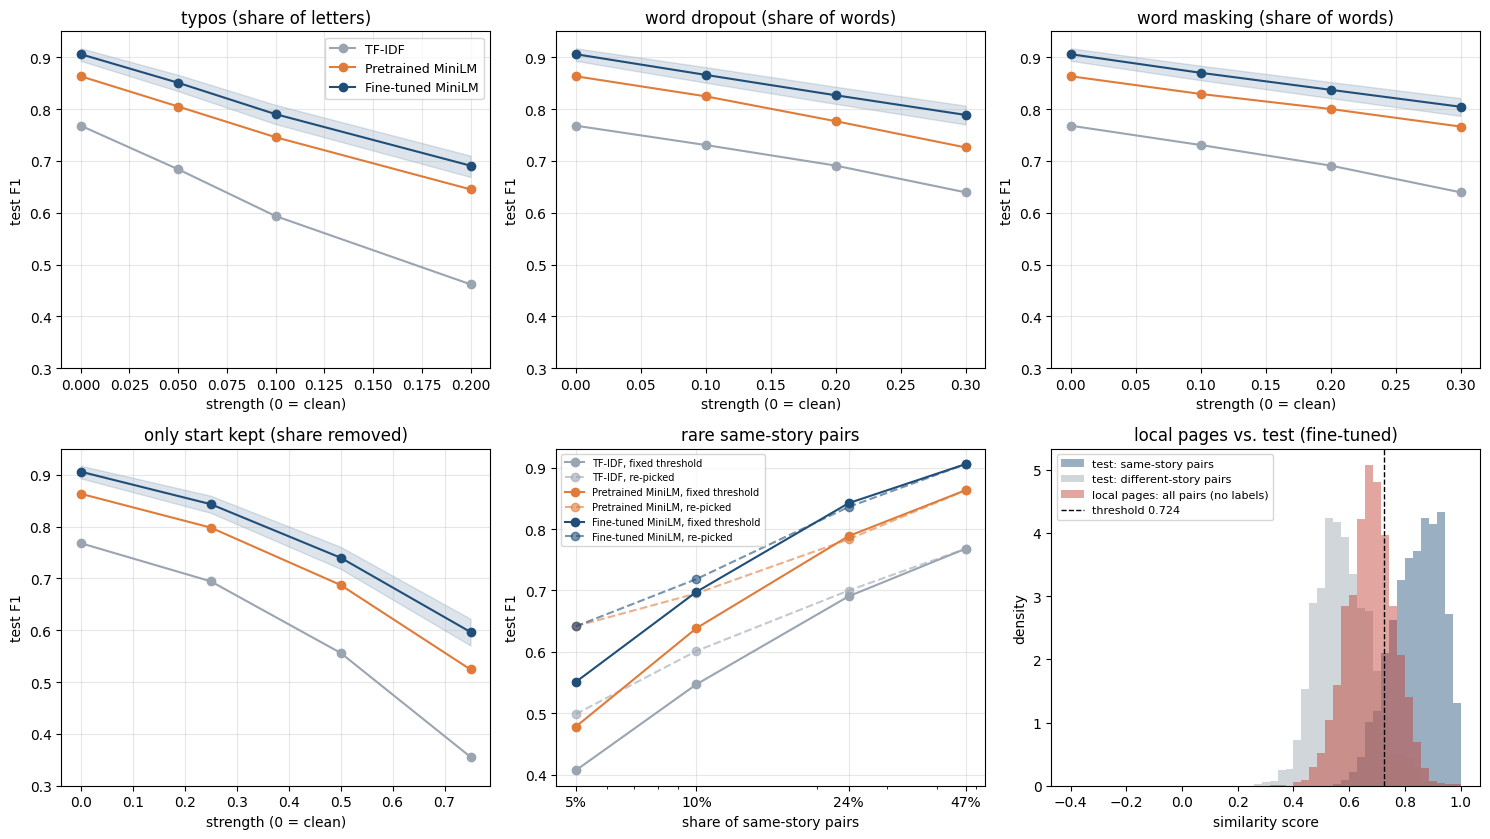

In [10]:
colors = {'TF-IDF': '#9aa5b1', 'Pretrained MiniLM': '#e07b39', 'Fine-tuned MiniLM': '#1f4e79'}
curves = list(CORRUPTIONS)[:4]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, test in zip(axes.flat, curves):
    for name in SCORERS:
        d = pd.concat([stress[(stress.test == 'clean') & (stress.model == name)],
                       stress[(stress.test == test) & (stress.model == name)]])
        ax.plot(d.level, d.f1, 'o-', color=colors[name], label=name)
        if name == 'Fine-tuned MiniLM':
            ax.fill_between(d.level.astype(float), d.f1_lo.astype(float), d.f1_hi.astype(float), color=colors[name], alpha=0.15)
    ax.set_title(test); ax.set_xlabel('strength (0 = clean)'); ax.set_ylabel('test F1'); ax.set_ylim(0.3, 0.95); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=9)

ax = axes[1, 1]
r = rarity.groupby(['model', 'share']).mean(numeric_only=True).reset_index()
for name in SCORERS:
    d = r[r.model == name]
    ax.plot(d.share, d.f1, 'o-', color=colors[name], label=f'{name}, fixed threshold')
    ax.plot(d.share, d.f1_repicked, 'o--', color=colors[name], alpha=0.6, label=f'{name}, re-picked')
ax.set_xscale('log'); ax.set_xticks([0.05, 0.10, 0.24, 0.47]); ax.set_xticklabels(['5%', '10%', '24%', '47%'])
ax.set_title('rare same-story pairs'); ax.set_xlabel('share of same-story pairs'); ax.set_ylabel('test F1'); ax.grid(alpha=0.3)
ax.legend(fontsize=7)

ax = axes[1, 2]
bins = np.linspace(-0.4, 1, 50)
for (g, s), c in zip(groups.items(), ['#1f4e79', '#9aa5b1', '#c0392b']):
    ax.hist(s, bins=bins, density=True, alpha=0.45, color=c, label=g)
ax.axvline(t, color='k', ls='--', lw=1, label=f'threshold {t:.3f}')
ax.set_title('local pages vs. test (fine-tuned)'); ax.set_xlabel('similarity score'); ax.set_ylabel('density'); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'robustness_curves.png', dpi=150)
plt.show()